# Importações - Bibliotecas

In [54]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
#import seaborn as sns

# BD

In [55]:
import os
import kagglehub

In [56]:
tsp_path = kagglehub.dataset_download("ziya07/traveling-salesman-problem-tsplib-dataset")

In [57]:
tsp_db = pd.read_csv(os.path.join(tsp_path,"tsp_dataset.csv"))

In [58]:
num_cities = tsp_db["num_cities"].copy()
#dist_mat = tsp_db["distance_matrix"].copy()
dist_mat = tsp_db["distance_matrix"].astype(str).tolist()

In [59]:
#Tratar os dados das matrizes de distâncias
for i in range(len(dist_mat)):
  dist_mat[i] = dist_mat[i].replace("[", "")
  dist_mat[i] = dist_mat[i].replace("]", "")
  dist_mat[i] = dist_mat[i].split(",")
  dist_mat[i] = [float(x) for x in dist_mat[i]]
  dist_mat[i] = np.reshape(dist_mat[i], (num_cities[i], num_cities[i]))

# Criar População

In [60]:
# Cria população de genótipos e retorna no formato de array de genótipos (permutações)
def generate_population(pop_size, n_stops):
  population = []
  population_size = pop_size
  for i in range(population_size):
    population.append(np.random.permutation(n_stops))
  return population

# Laço
    Cálculo de fitness - Erro

    Seleção

    Reprodução - Crossing Over

    Mutação

Fitness

In [61]:
#Calcula a fitness (distância total) de um genótipo

def calculate_fitness(genotype: list, dist_mat: list):
  distance = 0
  for i in range(len(genotype)-1):
    distance += dist_mat[genotype[i]][genotype[i+1]]
  return distance

In [62]:
#Faz esse de cima várias vezes
#Calcula a fitness de uma população de genótipos e ordena do melhor para o pior

def population_fitness(population, dist_mat):
  population_fitness = []
  for i in range(len(population)):
    population_fitness.append([i, calculate_fitness(population[i], dist_mat)])
  population_fitness.sort(key=lambda x: x[1], reverse=False)
  return(population_fitness)

Selection

In [63]:
#Seleciona os primeiros 5 (melhores) genótipos e retorna eles

def select_best_elitism(population_fitness: list, population: list, survival_rate: float):
  best_fitted_genotypes = []
  population_fitness = population_fitness[:round(len(population_fitness)*survival_rate)]
  index, _ = zip(*population_fitness)
  for i in index:
    best_fitted_genotypes.append(population[i])
  return best_fitted_genotypes

Reproduction

In [64]:
#Reproduz os genótipos da entrada aleatoriamente e inclui junto aos pais para formar uma populacao cheia

def reproduce(parents: list, amount: int):
  offspring = parents.copy()
  while len(offspring) < amount:
    xo_point = np.random.randint(0, len(parents[0]))
    p1 = np.random.randint(0, len(parents))
    p2 = np.random.randint(0, len(parents))
    while p1 == p2:
      p2 = np.random.randint(0, len(parents))
    kid = list(parents[p1][:xo_point])
    for j in parents[p2]:
      if j in kid:
        continue
      else:
        kid.append(j)
    offspring.append(kid)
  return offspring

Mutation

In [65]:
#Gera pequenas alterações numa população de genótipos - Daria para separar em dois para manter mais coerente com as outras funções

def mutate(population, mut_prob):
  for i in range(len(population)):
    if np.random.rand() < mut_prob:
      m1 = np.random.randint(0, len(population[i]))
      m2 = np.random.randint(0, len(population[i]))
      population[i][m1], population[i][m2] = population[i][m2], population[i][m1]
  return population

Loop

In [66]:
#Loop de começo ao fim que retorna o melhor resultado obtido em formato [genótipo, r2], histórico de melhores geracionais e média do fitness
def population_loop(pop_size = 50, db_num_cities = num_cities, db_dist_mat = dist_mat, epochs = 100, survival_rate = .5, mut_prob = .1, seed = 42):
  n = seed

  num_cities = db_num_cities[n]
  dist_mat = db_dist_mat[n]

  curr_best = [[],[]]
  best_generation_result = []
  fit_mean = []

  pop = generate_population(pop_size, num_cities)

  for i in range(epochs):
    #population_prediction = population_fenotypes(population)
    pop_fit = population_fitness(pop, dist_mat)
    _, results = zip(*pop_fit)
    fit_mean.append(np.mean(results))
    pop_best = select_best_elitism(pop_fit, pop, survival_rate)

    if(i == 0 or pop_fit[0][1] < curr_best[1]):
      curr_best[0] = pop_best[0]
      curr_best[1] = pop_fit[0][1]
    best_generation_result.append(pop_best[0])

    pop = reproduce(pop_best, pop_size)
    pop = mutate(pop, mut_prob)
  last_gen_results = results
  print(pd.DataFrame(pop))
  return curr_best, best_generation_result, fit_mean, last_gen_results

Gráficos e resultados

In [67]:
#Converte um genótipo nos valores x e y para plotar uma função
def predict_list(genotype: list, iterations: list):
  fenotype = []
  for i in iterations:
    fenotype.append(genotype[0] * i**2 + genotype[1] * i + genotype[2])
  return fenotype

In [68]:
#Faz esse de cima várias vezes, basicamente
#Converte a população (array de genótipos) inteira em valores x e y para plotar funções

def population_fenotypes(population: list):
  population_prediction = []
  for i in range(len(population)):
    population_prediction.append(predict_list(population[i], i))
  return population_prediction

In [69]:
#Plota apenas um gráfico com base no genótipo individual inserido

def plot_genotype(genotype, data_x):
  plt.scatter(data_x, predict_list(genotype, data_x))
  #sns.lineplot(x=data_x, y=predict_list(genotype, data_x), label="Genótipo: " + str(genotype))
  #sns.lineplot(x=data_x, y=predict_list(genotype, data_x), alpha=0.2)

In [70]:
#Plota apenas os dados

def plot_data(data_x, data_y):
    plt.scatter(data_x, data_y)
    #sns.scatterplot(x=data_x, y=data_y, label="Dados")

In [71]:
#Plota um genótipo e o compara com os dados

def plot_single_comparison(data_x, data_y, genotype):
  plot_data(data_x, data_y)
  plot_genotype(genotype, data_x)
  plt.legend()
  plt.show()

In [72]:
#Plota todos os gráficos de uma população inteira de genótipos

def plot_population(population):
  for i in range(len(population)):
    plot_genotype(population[i])

In [73]:
#Plota todos os gráficos de uma população e plota os dados

def plot_population_comparison(population, data_x, data_y):
  plot_data(data_x, data_y)
  for i in range(len(population)):
    plot_genotype(population[i], data_x)

# Execução

In [74]:
ps = 1000
ep = 500
mp = .01
sr = .2
n = 2

In [75]:
boa, bgh, fm, lgr = population_loop(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)

     0   1   2   3   4   5   6   7   8   9   ...  88  89  90  91  92  93  94  \
0    31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
1    31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
2    31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
3    31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
4    31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
..   ..  ..  ..  ..  ..  ..  ..  ..  ..  ..  ...  ..  ..  ..  ..  ..  ..  ..   
995  31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
996  31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
997  31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
998  31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   
999  31  57  91  23   2  54  86  59   6  25  ...  92  26  79  30  89  84  81   

     95  96  97  
0    28  49  24  
1  

In [76]:
print(boa[1])
print(population_fitness(bgh,dist_mat[n]))
print(fm)
print(lgr)

1536.6141740666733
[[495, np.float64(1536.6141740666733)], [496, np.float64(1536.6141740666733)], [497, np.float64(1536.6141740666733)], [498, np.float64(1536.6141740666733)], [499, np.float64(1536.6141740666733)], [477, np.float64(1540.9952137238063)], [478, np.float64(1540.9952137238063)], [479, np.float64(1540.9952137238063)], [480, np.float64(1540.9952137238063)], [481, np.float64(1540.9952137238063)], [482, np.float64(1540.9952137238063)], [483, np.float64(1540.9952137238063)], [484, np.float64(1540.9952137238063)], [485, np.float64(1540.9952137238063)], [486, np.float64(1540.9952137238063)], [487, np.float64(1540.9952137238063)], [488, np.float64(1540.9952137238063)], [489, np.float64(1540.9952137238063)], [490, np.float64(1540.9952137238063)], [491, np.float64(1540.9952137238063)], [492, np.float64(1540.9952137238063)], [471, np.float64(1544.6166755486768)], [472, np.float64(1544.6166755486768)], [473, np.float64(1544.6166755486768)], [474, np.float64(1544.6166755486768)], [475,

# Plot de gráficos

Resultados pós-treino

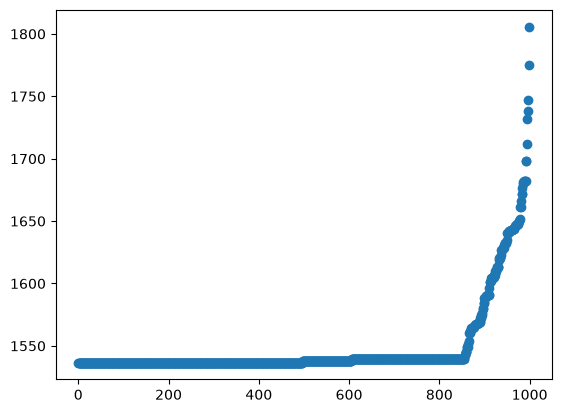

In [77]:
plot_data(range(0,ps), lgr)

Histórico

    1º Média de Fitness de cada geração
    2º Melhor Fitness de cada geração 

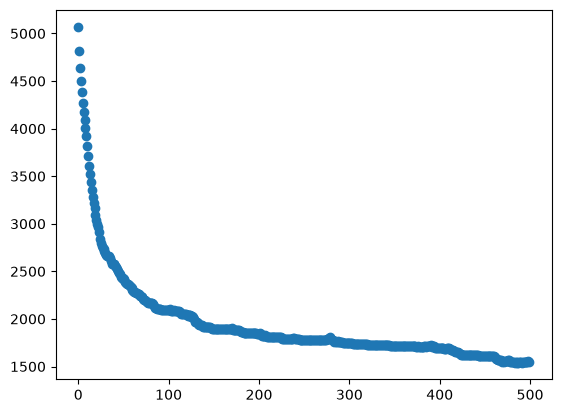

In [78]:
plot_data(range(0,ep), fm)

In [79]:
dados = population_fitness(bgh, dist_mat[n])
best_generation_history = [fila[1] for fila in sorted(dados, key=lambda x: float(x[0]))]
#best_generation_history = [float(fila[1]) for fila in population_fitness(bgh, dist_mat[n])]

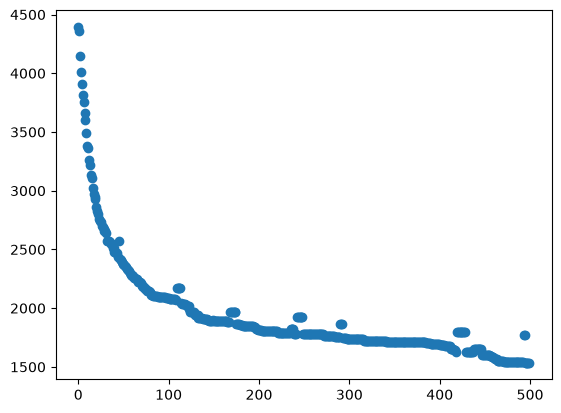

In [80]:
plot_data(range(0,ep), best_generation_history)